<!-- # Machine Learning Revision & Practical
## Diamonds Dataset — EDA, Visualization & ML Algorithms -->

# Machine Learning Revision & Practical
## Diamonds Dataset — EDA, Visualization & ML Algorithms

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Train-Test Split
from sklearn.model_selection import train_test_split

# Feature Scaling
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Regression
from sklearn.linear_model import LinearRegression

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv('diamonds.csv')

In [4]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
df.shape

(53940, 11)

In [6]:
df.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='str')

In [7]:
df.info()             

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  str    
 3   color       53940 non-null  str    
 4   clarity     53940 non-null  str    
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 4.5 MB


In [8]:
df.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

In [9]:
df.describe()     #numerical values ka statistical summary

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

Unnamed: 0      int64
carat         float64
cut               str
color             str
clarity           str
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

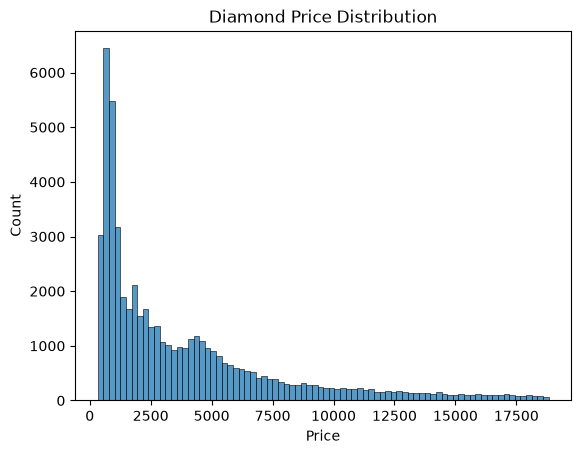

In [12]:
sns.histplot(data=df, x='price')
plt.title('Diamond Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

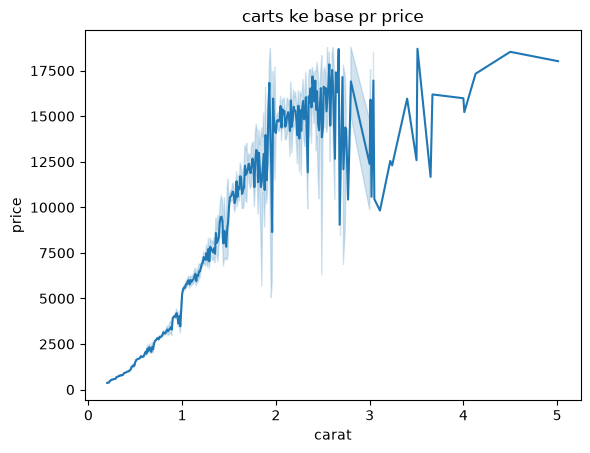

In [13]:
df = df.sort_values(by = 'carat',ascending=True)

sns.lineplot(data = df,x = 'carat', y = 'price')
plt.title('carts ke base pr price')
plt.xlabel('carat')
plt.ylabel('price')
plt.show()

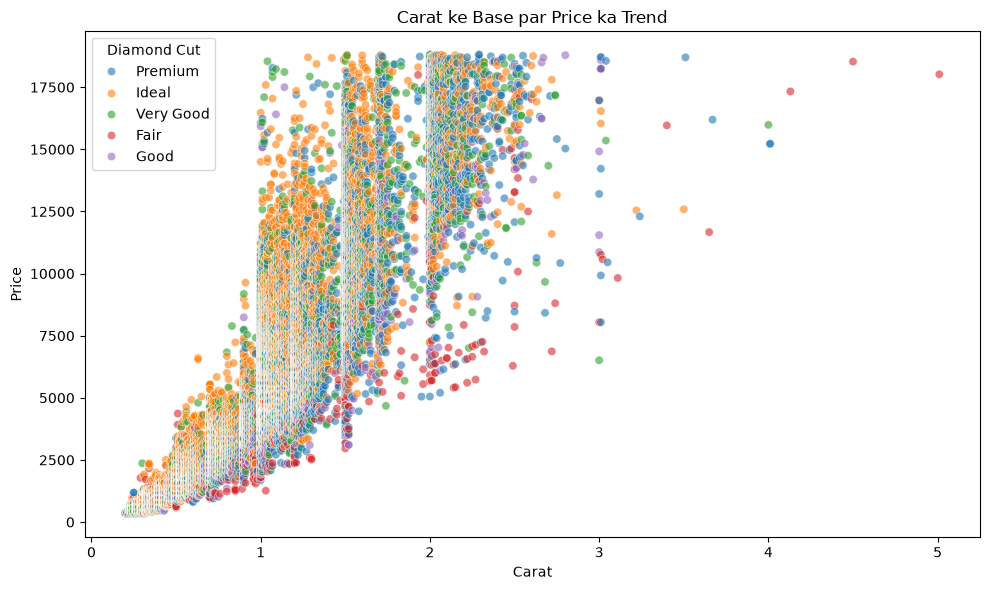

In [14]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(10, 6))

# Carat aur price ka scatterplot bana rahe hain
# hue='cut' se har cut ko alag colour milega
# alpha se dots ki transparency set hoti hai
sns.scatterplot(data=df, x='carat', y='price', hue='cut', alpha=0.6)

# Graph ka title set kar rahe hain
plt.title('Carat ke Base par Price ka Trend')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Carat')
plt.ylabel('Price')

# Legend ka title set kar rahe hain
plt.legend(title='Diamond Cut')

# Graph ki spacing ko adjust kar rahe hain
plt.tight_layout()

# Graph display kar rahe hain
plt.show()


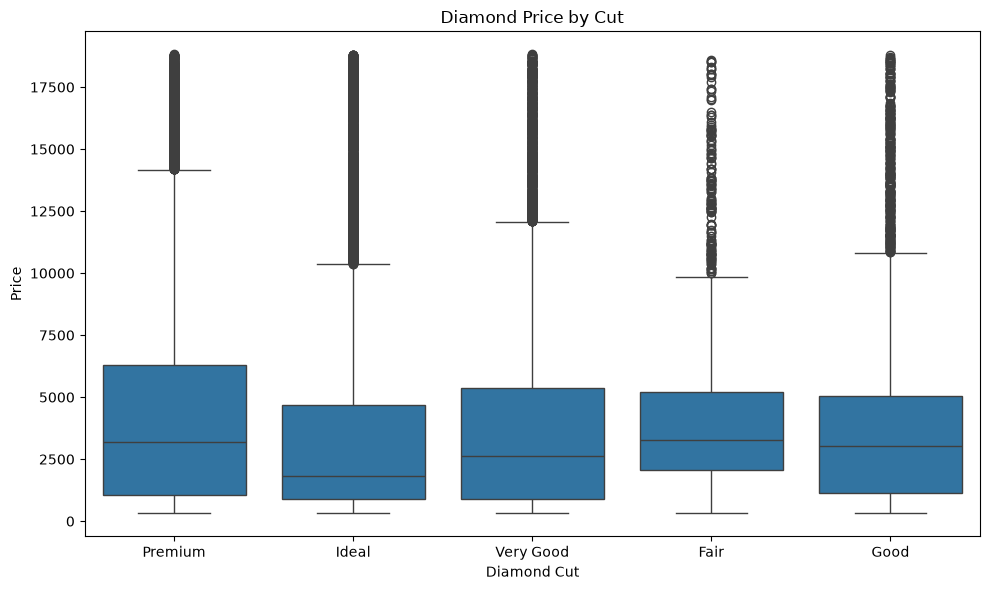

In [15]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(10, 6))

# Cut ke hisaab se diamond prices ka boxplot bana rahe hain
sns.boxplot(data=df, x='cut', y='price')

# Graph ka title set kar rahe hain
plt.title('Diamond Price by Cut')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Diamond Cut')
plt.ylabel('Price')

# Graph ki spacing adjust kar rahe hain
plt.tight_layout()

# Graph display kar rahe hain
plt.show()


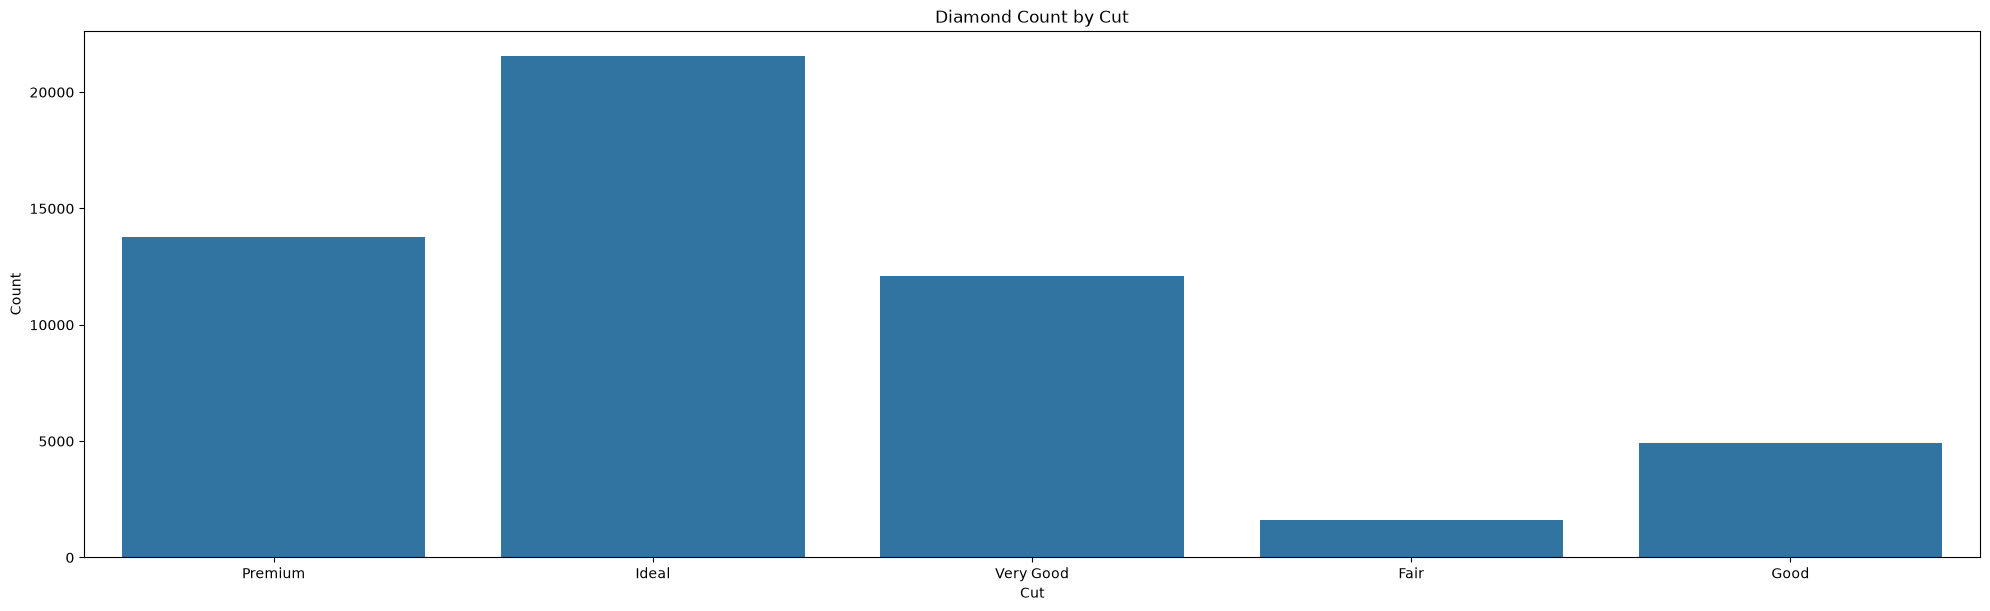

In [16]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(20, 6))

# Har cut category ke diamonds ki counting dikha rahe hain
sns.countplot(data=df, x='cut')

# Graph ki spacing adjust kar rahe hain
plt.tight_layout()

# Graph ka title set kar rahe hain
plt.title('Diamond Count by Cut')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Cut')
plt.ylabel('Count')

# Graph display kar rahe hain
plt.show()


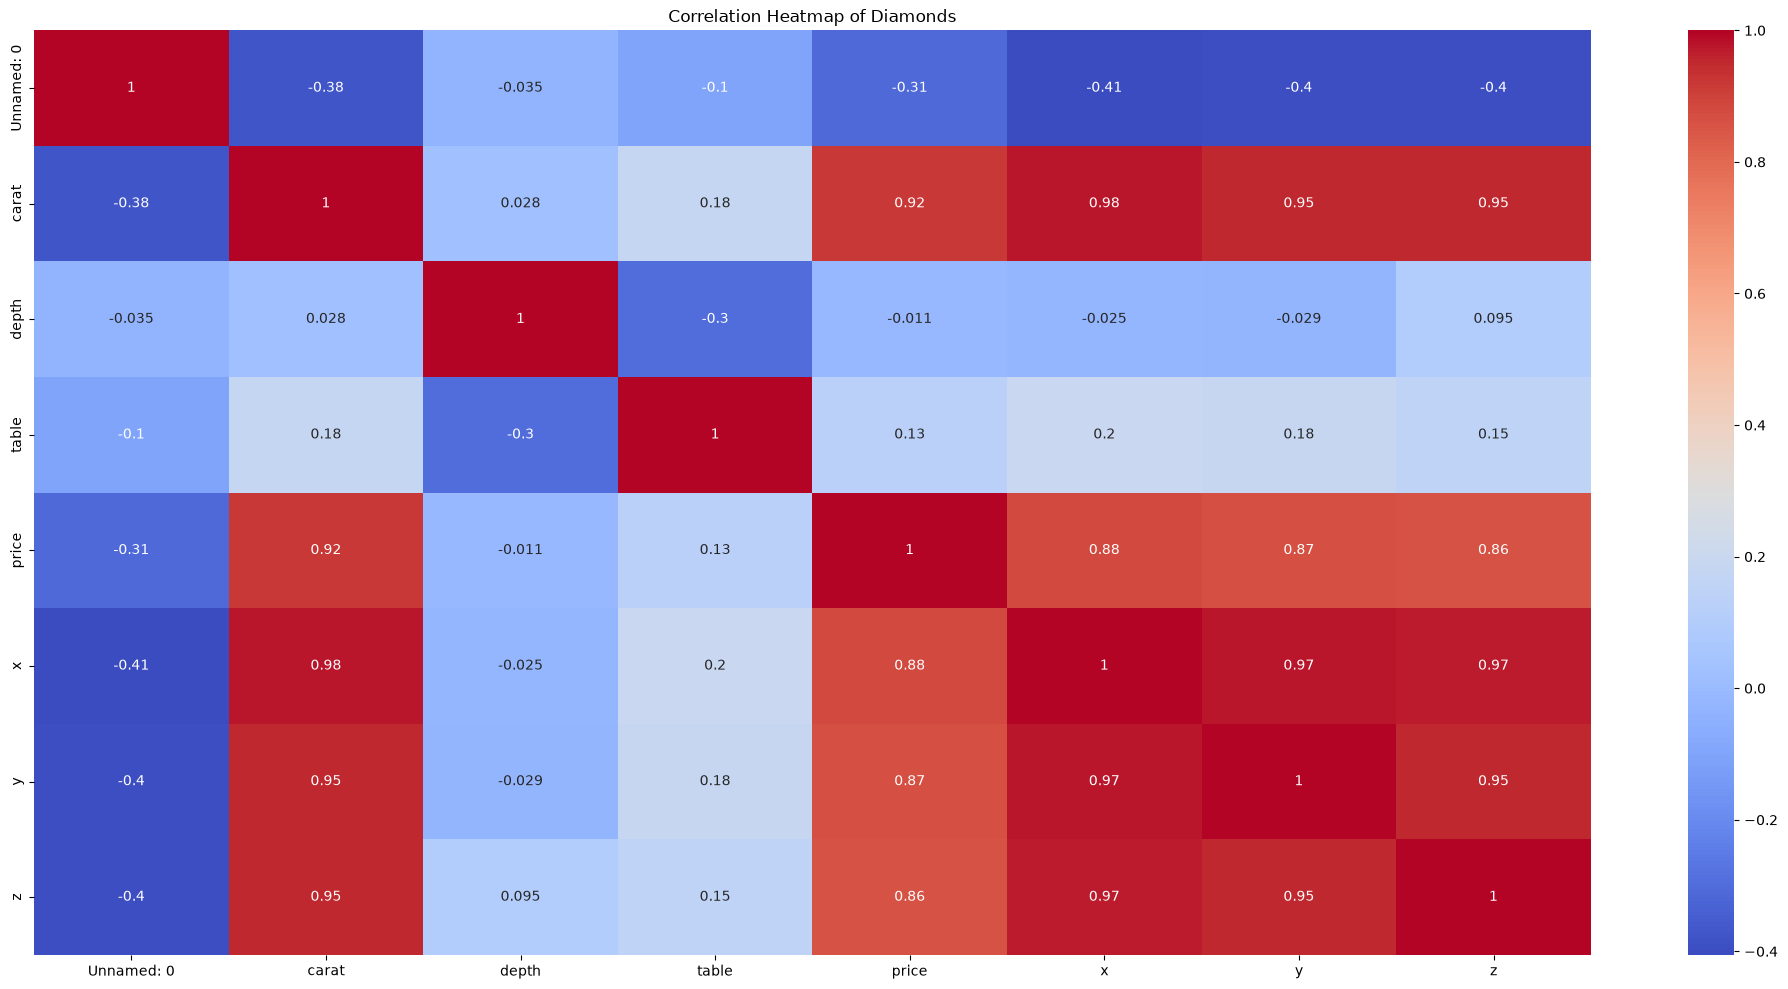

In [17]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(20,10))

# Numerical columns ka correlation calculate karke heatmap bana rahe hain
sns.heatmap(data=df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')  #annot=True har box mein value dikhata hai aur cmap='coolwarm' colours set karta hai.

# Graph ka title set kar rahe hain
plt.title('Correlation Heatmap of Diamonds')

# Graph ki spacing adjust kar rahe hain
plt.tight_layout()

# Graph display kar rahe hain
plt.show()

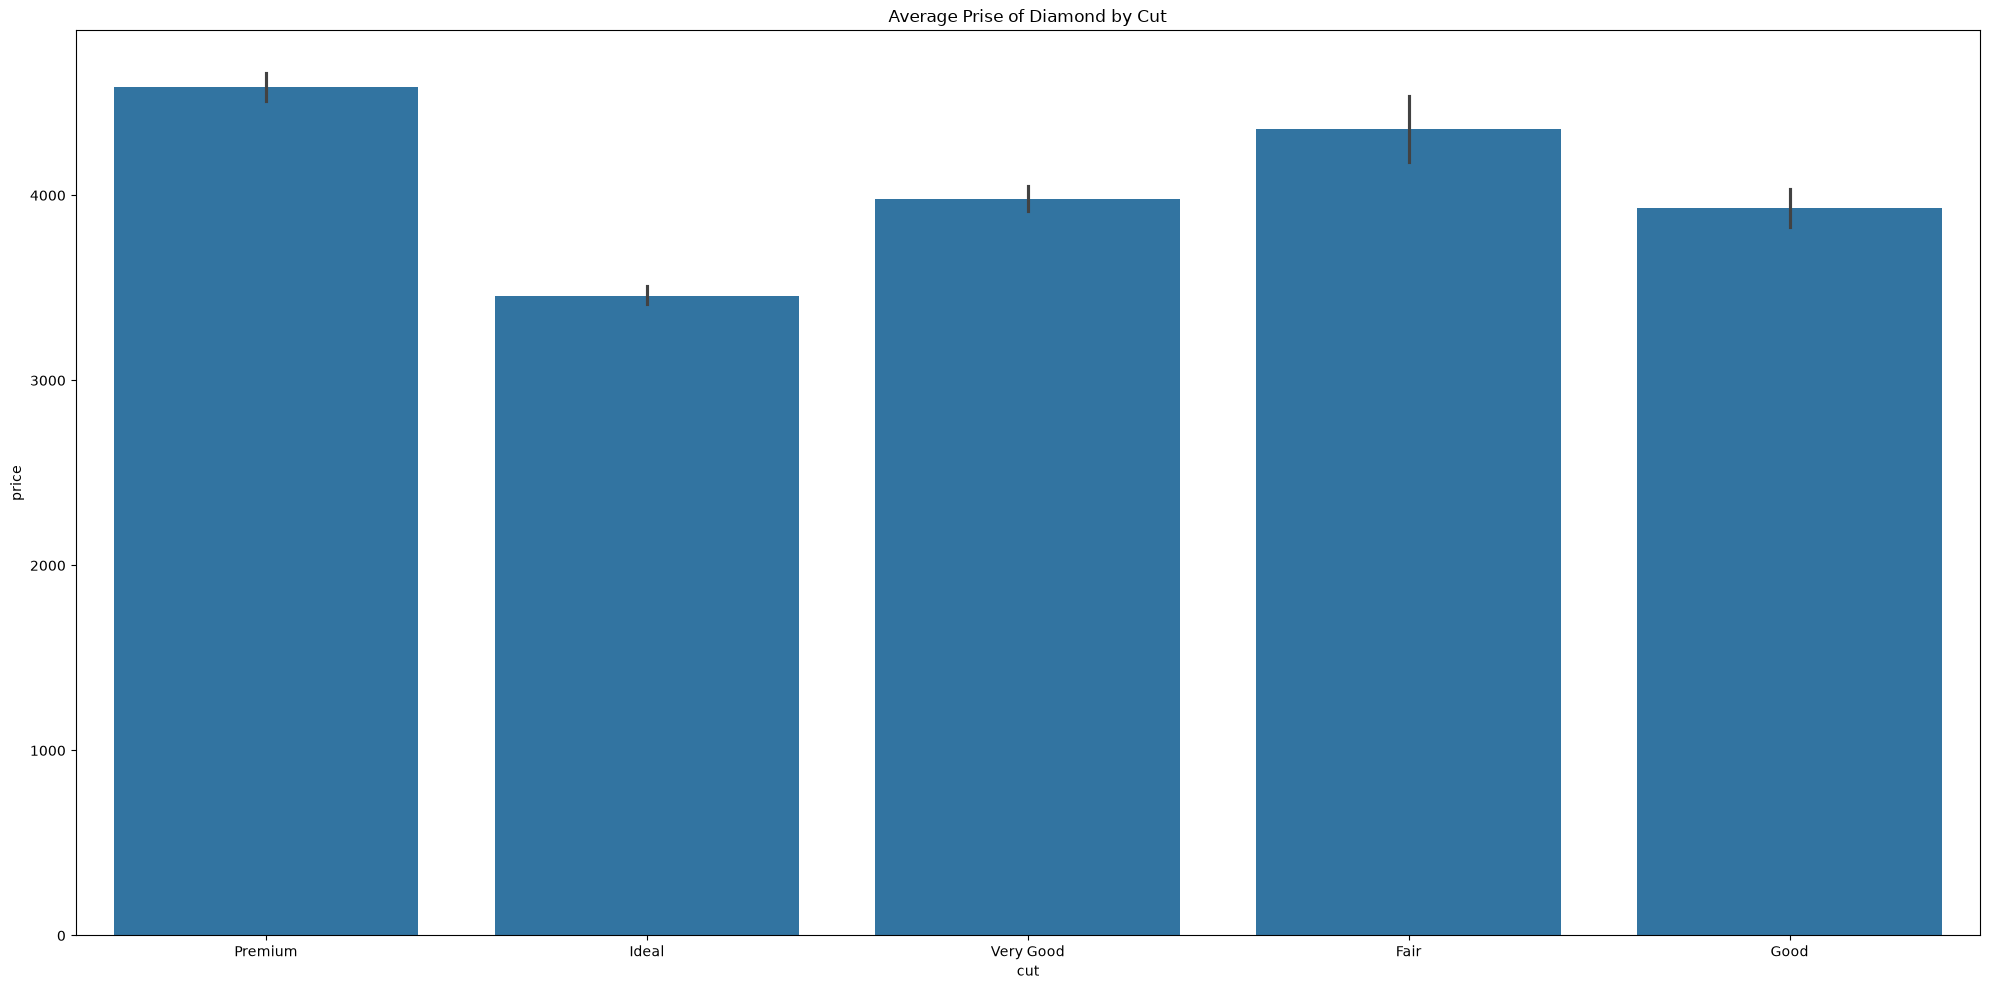

In [18]:
plt.figure(figsize=(20,10))
sns.barplot(data = df, x = 'cut', y = 'price')
plt.title('Average Prise of Diamond by Cut')
plt.xlabel('cut')
plt.ylabel('price')
plt.tight_layout()
plt.show()

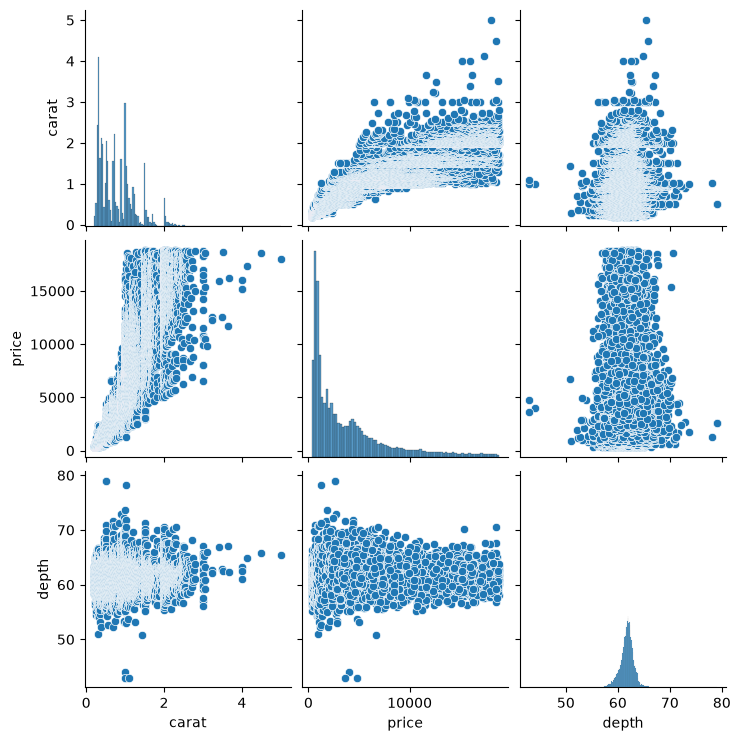

In [19]:
sns.pairplot(data = df[['carat','price','depth']])
plt.show()

In [49]:
# 1. Input aur Target
X = df[['carat']]
y = df['price']

# 2. Training aur Testing Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 5. Training Performance
print("=" * 40)
print("LINEAR REGRESSION - PRICE")
print("TRAINING PERFORMANCE")
print("=" * 40)

print("R2 Score:", r2_score(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))

train_mse = mean_squared_error(y_train, y_train_pred)
print("MSE:", train_mse)
print("RMSE:", np.sqrt(train_mse))

# 6. Testing Performance
print("\n" + "=" * 40)
print("TESTING PERFORMANCE")
print("=" * 40)

print("R2 Score:", r2_score(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))

test_mse = mean_squared_error(y_test, y_test_pred)
print("MSE:", test_mse)
print("RMSE:", np.sqrt(test_mse))

LINEAR REGRESSION - PRICE
TRAINING PERFORMANCE
R2 Score: 0.8498804080167113
MAE: 1004.2470845757169
MSE: 2389314.804755
RMSE: 1545.7408595087988

TESTING PERFORMANCE
R2 Score: 0.847116897099127
MAE: 1015.6786215694367
MSE: 2432646.0215353672
RMSE: 1559.6942077007811


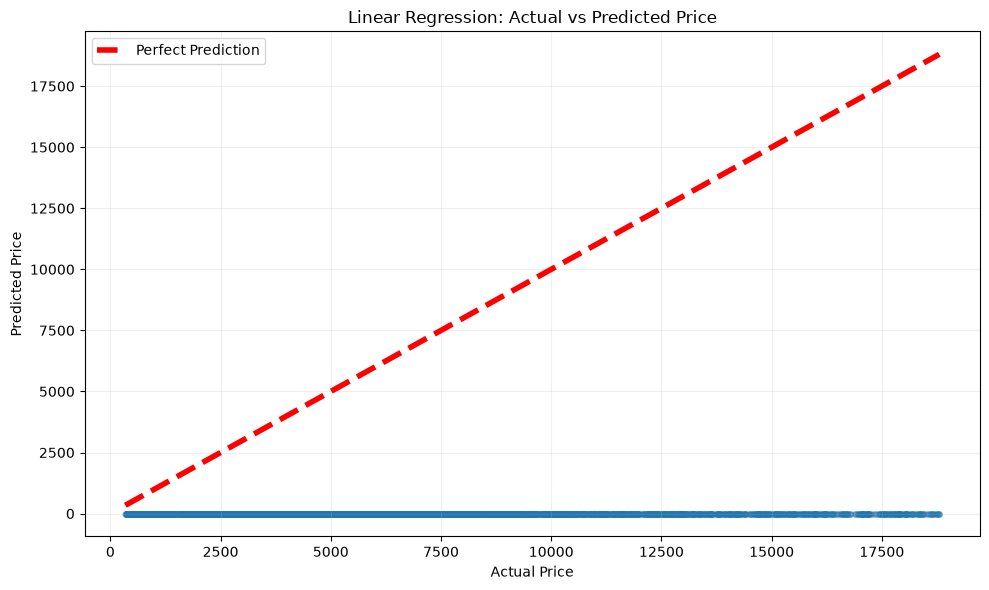

In [50]:

# Clean Linear Regression Graph

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.25,
    s=15
)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=4,
    label='Perfect Prediction'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted Price")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [34]:
df.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='str')

In [43]:
# 1. Input aur Target
X = df[['carat']]
y = df['cut']

# 2. Target labels numeric mein convert karo
le = LabelEncoder()
y = le.fit_transform(y)

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Logistic Regression Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 5. Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


# 6. Training aur Testing Performance
for name, y_true, y_pred in [
    ("TRAINING", y_train, y_train_pred),
    ("TESTING", y_test, y_test_pred)
]:
    print("\n" + "=" * 45)
    print(name, "PERFORMANCE")
    print("=" * 45)

    print("Accuracy:", accuracy_score(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        target_names=le.classes_,
        zero_division=0
    ))

    print("TP, TN, FP, FN (class-wise):")
    for i, class_name in enumerate(le.classes_):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - TP - FN - FP

        print(
            class_name,
            "| TP:", TP,
            "| TN:", TN,
            "| FP:", FP,
            "| FN:", FN
        )


# 7. New Carat Value Prediction
new_data = pd.DataFrame({'carat': [0.5]})
prediction = model.predict(new_data)
predicted_cut = le.inverse_transform(prediction)

print("\nPredicted Cut:", predicted_cut[0])


TRAINING PERFORMANCE
Accuracy: 0.4099925843529848

Confusion Matrix:
[[    0     0  1018   270     0]
 [    0     0  3368   557     0]
 [    0     0 15690  1551     0]
 [    0     0  9031  2002     0]
 [    0     0  8440  1225     0]]

Classification Report:
              precision    recall  f1-score   support

        Fair       0.00      0.00      0.00      1288
        Good       0.00      0.00      0.00      3925
       Ideal       0.42      0.91      0.57     17241
     Premium       0.36      0.18      0.24     11033
   Very Good       0.00      0.00      0.00      9665

    accuracy                           0.41     43152
   macro avg       0.16      0.22      0.16     43152
weighted avg       0.26      0.41      0.29     43152

TP, TN, FP, FN (class-wise):
Fair | TP: 0 | TN: 41864 | FP: 0 | FN: 1288
Good | TP: 0 | TN: 39227 | FP: 0 | FN: 3925
Ideal | TP: 15690 | TN: 4054 | FP: 21857 | FN: 1551
Premium | TP: 2002 | TN: 28516 | FP: 3603 | FN: 9031
Very Good | TP: 0 | TN: 33487

In [52]:
# Randum Forest 

# 1. Input aur Target
X = df[['carat']]
y = df['price']

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# 4. Model Training
model.fit(X_train, y_train)

# 5. Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 6. Training Performance
print("TRAINING PERFORMANCE")
print("R2 Score:", r2_score(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))

train_mse = mean_squared_error(y_train, y_train_pred)
print("MSE:", train_mse)
print("RMSE:", np.sqrt(train_mse))

# 7. Testing Performance
print("\nTESTING PERFORMANCE")
print("R2 Score:", r2_score(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))

test_mse = mean_squared_error(y_test, y_test_pred)
print("MSE:", test_mse)
print("RMSE:", np.sqrt(test_mse))


TRAINING PERFORMANCE
R2 Score: 0.8762168760190514
MAE: 804.5085876558807
MSE: 1970141.583780933
RMSE: 1403.6173209892122

TESTING PERFORMANCE
R2 Score: 0.8689903919618485
MAE: 816.2395304797129
MSE: 2084599.2508639575
RMSE: 1443.814133073907
